In [1]:
import numpy as np 
import tensorflow as tf 
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd 
sns.set_style("whitegrid")
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
path = "/kaggle/input/bank-transaction-dataset-for-fraud-detection/bank_transactions_data_2.csv"
df = pd.read_csv(path)

In [3]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


## Features
- **TransactionID**: Unique identifier for each transaction (e.g., TX000001).
- **AccountID**: Unique identifier for the account (e.g., AC00128).
- **TransactionAmount**: Amount of the transaction in dollars (e.g., 14.09).
- **TransactionDate**: Date and time of the transaction (e.g., 2023-04-11 16:29:14).
- **TransactionType**: Type of transaction (Debit or Credit).
- **Location**: City where the transaction occurred (e.g., San Diego).
- **DeviceID**: Identifier for the device used (e.g., D000380).
- **IP Address**: IP address of the transaction (e.g., 162.198.218.92).
- **MerchantID**: Identifier for the merchant involved (e.g., M015).
- **Channel**: Method of transaction (ATM, Online, Branch).
- **CustomerAge**: Age of the account holder (e.g., 70).
- **CustomerOccupation**: Occupation of the account holder (e.g., Doctor).
- **TransactionDuration**: Time taken for the transaction in seconds (e.g., 81).
- **LoginAttempts**: Number of login attempts before the transaction (e.g., 1).
- **AccountBalance**: Balance in the account after the transaction (e.g., 5112.21).
- **PreviousTransactionDate**: Date and time of the previous transaction (e.g., 2024-11-04 08:08:08).

In [4]:
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


## Statistical Insights

### Transaction Amount

- **Mean**: $297.59
Transactions average around $300, a typical spending benchmark.
- **Standard Deviation**: $291.95
A wide spread reveals diverse transaction sizes.
- **Minimum**: $0.27
Some transactions are nearly trivial in value.
- **Maximum**: $1,919.11
The top transaction dwarfs the mean, suggesting outliers.
- **Insight**: The right-skewed distribution—many small transactions, few large ones—is typical and may highlight anomalies.

### Customer Age

- **Mean**: 44.67 years
Customers average 45 years, indicating a mature base.
- **Standard Deviation**: 17.79 years
Ages vary broadly, spanning multiple generations.
- **Minimum**: 18 years
The youngest are just of legal age.
- **Maximum**: 80 years
The oldest reach senior years.
- **Insight**: This age diversity allows segmentation to explore transaction trends across life stages.

### Transaction Duration

- **Mean**: 119.64 seconds (~2 minutes)
Most transactions wrap up in about two minutes.
- **Standard Deviation**: 69.96 seconds
Durations fluctuate noticeably.
- **Minimum**: 10 seconds
Some are lightning-fast.
- **Maximum**: 300 seconds (5 minutes)
Others stretch to five minutes.
- **Insight**: Duration swings might reflect transaction type or flag suspicious delays.

### Login Attempts

- **Mean**: 1.12
Typically, just over one login attempt per transaction.
- **Standard Deviation**: 0.60
Variation is modest but present.
- **Minimum**: 1
At least one attempt is universal.
- **Maximum**: 5
Rare cases hit five attempts.
- **Insight**: Higher attempts (e.g., 5) could signal security risks or fraud efforts.


### Account Balance

- **Mean**: 5,114.30
Account balances typically hover around 5,100.
- **Standard Deviation**: 3,900.94
A broad spread indicates significant financial variation.
- **Minimum**: 101.25
Certain accounts hold minimal funds.
- **Maximum**: 14,977.99
Some balances approach 15,000.
- **Insight**: The diversity in balances could shape unique transaction behaviors, offering clues for fraud detection.


In [5]:
df.dtypes

TransactionID               object
AccountID                   object
TransactionAmount          float64
TransactionDate             object
TransactionType             object
Location                    object
DeviceID                    object
IP Address                  object
MerchantID                  object
Channel                     object
CustomerAge                  int64
CustomerOccupation          object
TransactionDuration          int64
LoginAttempts                int64
AccountBalance             float64
PreviousTransactionDate     object
dtype: object

# EDA

In [6]:
def style_plot(fig_size=(10, 6), title=None, xlabel=None, ylabel=None):
    plt.figure(figsize=fig_size)
    plt.title(title, fontsize=16, weight='bold', pad=15) if title else None
    plt.xlabel(xlabel, fontsize=12) if xlabel else None
    plt.ylabel(ylabel, fontsize=12) if ylabel else None
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    sns.despine()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


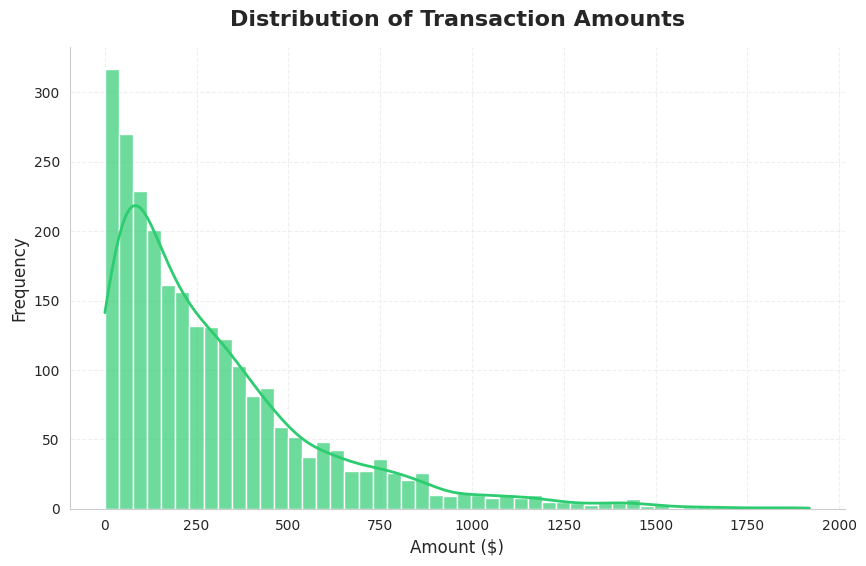

In [7]:
style_plot(title='Distribution of Transaction Amounts', xlabel='Amount ($)', ylabel='Frequency')
sns.histplot(df['TransactionAmount'], bins=50, kde=True, color='#2ecc71', 
             line_kws={'color': '#e74c3c', 'lw': 2}, alpha=0.7)
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

### **Outlier Identification**:
-  High-value transactions (e.g., >$1,500) are rare and could indicate potential fraud, as they deviate from the norm.**Pattern Recognition**: The concentration of small transactions suggests typical behavior, making anomalies (e.g., sudden large amounts) easier to flag.**Threshold Setting**: The distribution can guide setting thresholds for anomaly detection (e.g., flagging amounts above the 95th percentile) in your K-means clustering or other models.

- **Outlier Identification**: High-value transactions (e.g., >$1,500) are rare and could indicate potential fraud, as they deviate from the norm.
- **Pattern Recognition**: The concentration of small transactions suggests typical behavior, making anomalies (e.g., sudden large amounts) easier to flag.

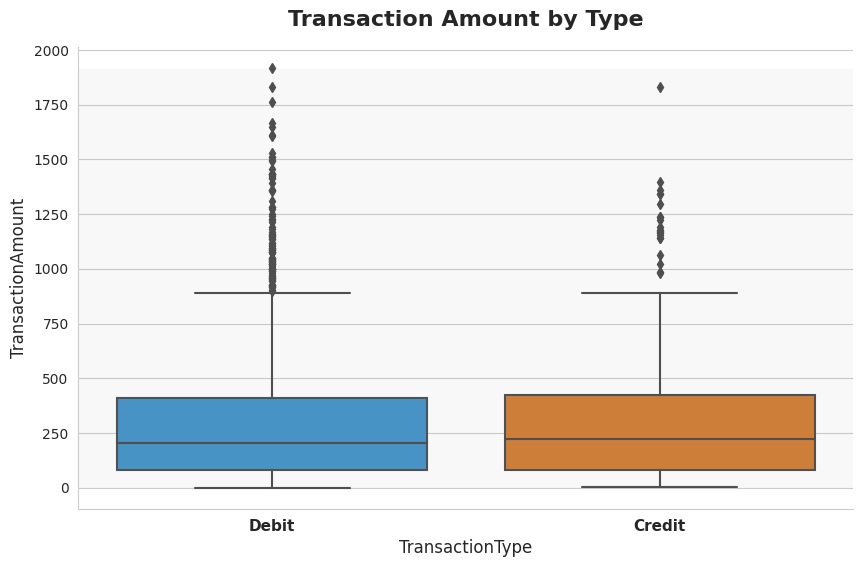

In [8]:
style_plot(title='Transaction Amount by Type', xlabel='Transaction Type', ylabel='Amount ($)')
sns.boxplot(x='TransactionType', y='TransactionAmount', data=df, 
            palette=['#3498db', '#e67e22'], linewidth=1.5, fliersize=5, saturation=0.8)
plt.xticks(fontsize=11, weight='bold')
plt.axhspan(0, df['TransactionAmount'].max(), facecolor='gray', alpha=0.05)
plt.show()

- **What It Shows**: Compares Debit and Credit transaction amounts, including medians, quartiles, and outliers.
- **Fraud Insight**:
    - Large debit transactions might indicate unauthorized withdrawals.
    - Credit outliers could suggest fraudulent refunds or money laundering.
- **Why It Helps**: Highlights differences in behavior between transaction types, which fraudsters might exploit differently.

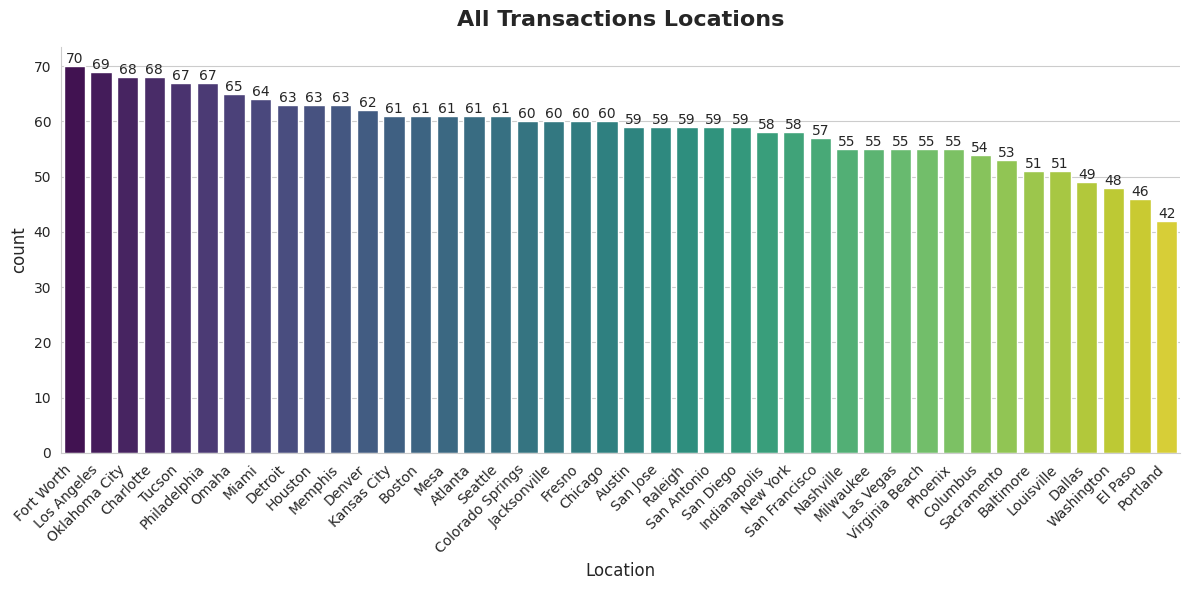

In [9]:
style_plot(fig_size=(12, 6), title='All Transactions Locations', xlabel='Location', ylabel='Number of Transactions')
top_locations = df['Location'].value_counts().index[:-1]
sns.countplot(x='Location', data=df, palette='viridis', order=top_locations)
plt.xticks(rotation=45, ha='right', fontsize=10)
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

**What It Shows**: Frequency of transactions across locations.**Fraud Insight**:

• High-frequency locations might be targets for fraud (e.g., skimming at ATMs).
• Low-frequency locations with large transactions could indicate spoofed origins.

- **What It Shows**: Frequency of transactions across locations.
- **Fraud Insight**:
    - • High-frequency locations might be targets for fraud (e.g., skimming at ATMs).
    - • Low-frequency locations with large transactions could indicate spoofed origins.
- **Why It Helps**: Pinpoints geographic hotspots for potential fraud monitoring.

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


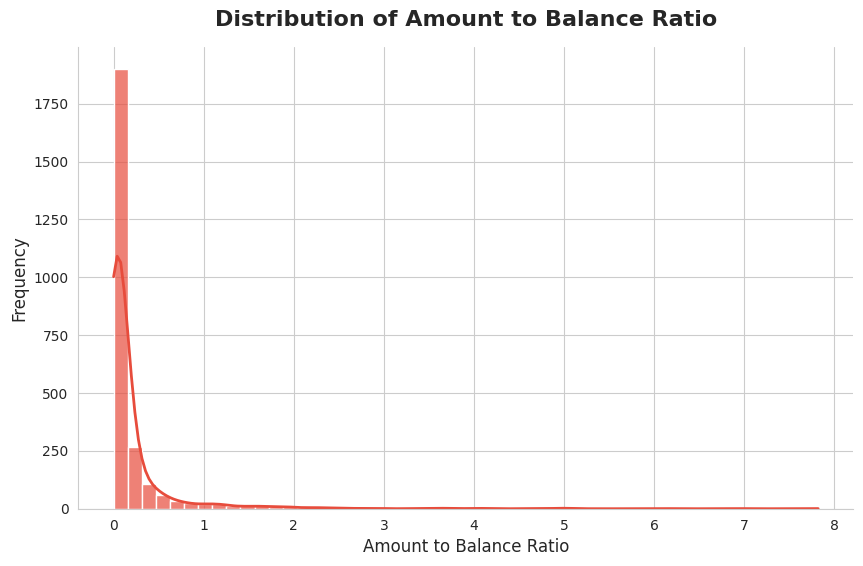

In [10]:
# Transaction Amount to Balance Ratio
df['Amount_to_Balance_Ratio'] = df['TransactionAmount'] / (df['AccountBalance'] + 1)  # Avoid division by zero
ax = style_plot(title='Distribution of Amount to Balance Ratio', 
                xlabel='Amount to Balance Ratio', ylabel='Frequency')
sns.histplot(df['Amount_to_Balance_Ratio'], bins=50, color='#e74c3c', kde=True, 
             line_kws={'color': '#2ecc71', 'lw': 2}, alpha=0.7)

plt.show()

/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


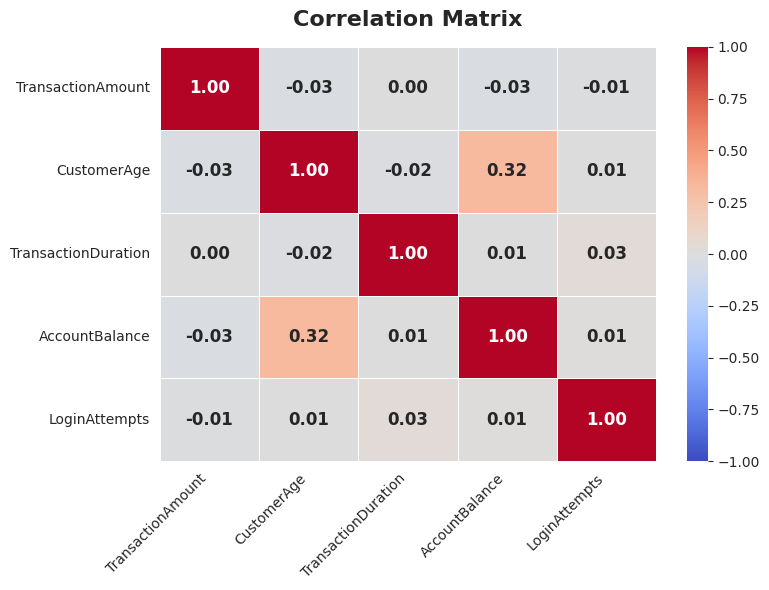

In [11]:
style_plot(fig_size=(8, 6), title='Correlation Matrix')
sns.heatmap(df[['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'AccountBalance', 'LoginAttempts']].corr(), 
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, 
            fmt='.2f', annot_kws={'size': 12, 'weight': 'bold'}, linewidths=0.5, linecolor='white')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

**Key Insight**: Most correlations are weak (close to 0), meaning features are largely independent. The strongest correlation is between CustomerAge and AccountBalance (0.32), suggesting older customers tend to have higher balances.**Fraud Detection Impact**: Low correlations imply features like TransactionAmount and LoginAttempts don’t move together, so they can each provide unique signals for detecting anomalies in fraud analysis.

- **Key Insight**: Most correlations are weak (close to 0), meaning features are largely independent. The strongest correlation is between CustomerAge and AccountBalance (0.32), suggesting older customers tend to have higher balances.
- **Fraud Detection Impact**: Low correlations imply features like TransactionAmount and LoginAttempts don’t move together, so they can each provide unique signals for detecting anomalies in fraud analysis.

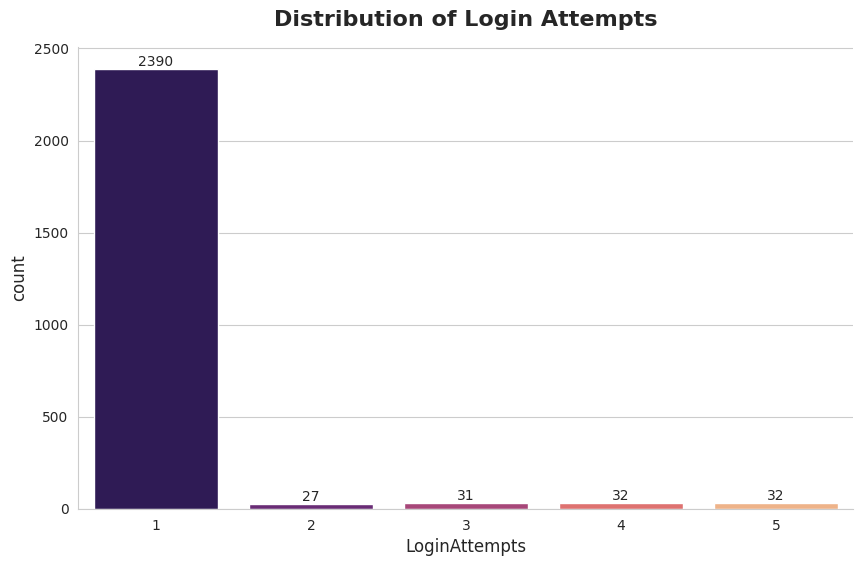

In [12]:
style_plot(title='Distribution of Login Attempts', xlabel='Number of Login Attempts', ylabel='Frequency')
sns.countplot(x='LoginAttempts', data=df, palette='magma')
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10)
plt.show()

**What It Shows**: How often multiple login attempts occur.**Fraud Insight**:

• Transactions with >1 login attempt might indicate account takeover attempts.
• Rare high values (e.g., 5 attempts) are red flags.**Why It Helps**: Highlights authentication anomalies, a key fraud indicator.

- **What It Shows**: How often multiple login attempts occur.
- **Fraud Insight**:
    - • Transactions with >1 login attempt might indicate account takeover attempts.
    - • Rare high values (e.g., 5 attempts) are red flags.
- **Why It Helps**: Highlights authentication anomalies, a key fraud indicator.

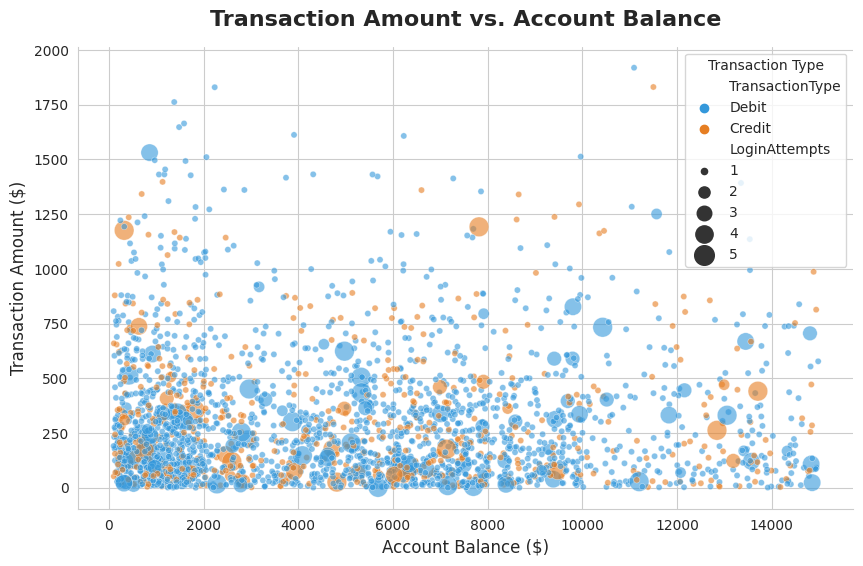

In [13]:

style_plot(fig_size=(10, 6), title='Transaction Amount vs. Account Balance', 
           xlabel='Account Balance ($)', ylabel='Transaction Amount ($)')
sns.scatterplot(x='AccountBalance', y='TransactionAmount', data=df, hue='TransactionType', 
                palette=['#3498db', '#e67e22'], size='LoginAttempts', sizes=(20, 200), alpha=0.6)
plt.legend(title='Transaction Type', fontsize=10)
plt.show()

- **What It Shows**: Relationship between transaction amount and remaining balance, colored by type and sized by login attempts.
- **Fraud Insight**:
    - • Large transactions with low balances (top-left corner) could indicate draining attempts.
    - • Points with larger sizes (more login attempts) might suggest fraud.
- **Why It Helps**: Visualizes risky combinations of features for anomaly detection.

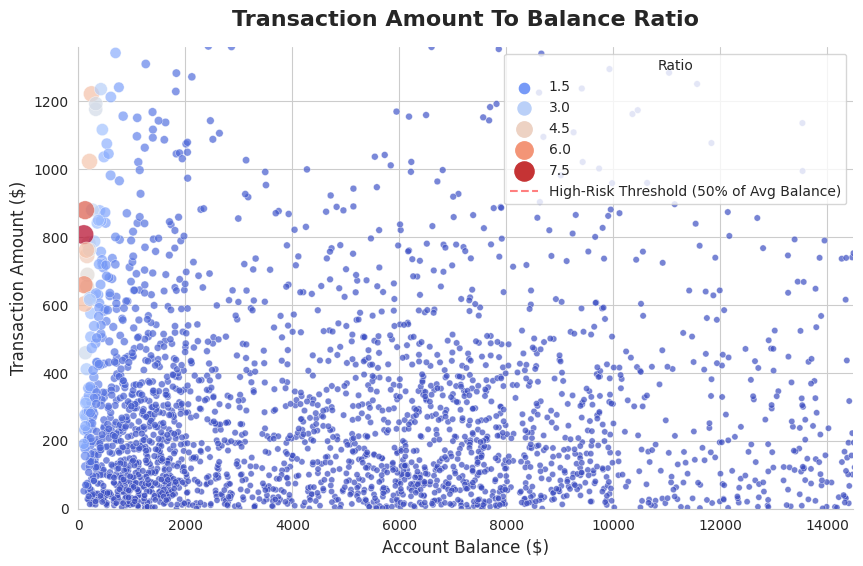

In [14]:
df['Amount_to_Balance_Ratio'] = df['TransactionAmount'] / (df['AccountBalance'] + 1e-6)
style_plot(fig_size=(10, 6), title='Transaction Amount To Balance Ratio', 
           xlabel='Account Balance ($)', 
           ylabel='Transaction Amount ($)')

# Scatter plot with color gradient based on ratio
sns.scatterplot(x='AccountBalance', y='TransactionAmount', hue='Amount_to_Balance_Ratio', 
                size='Amount_to_Balance_Ratio', sizes=(20, 200), 
                data=df, palette='coolwarm', alpha=0.7)

# Add a reference line for high-risk transactions (e.g., ratio > 0.5)
plt.axhline(y=df['AccountBalance'].mean() * 0.5, color='red', linestyle='--', alpha=0.5, 
            label='High-Risk Threshold (50% of Avg Balance)')
plt.legend(title='Ratio', fontsize=10)

# Limit axes for better visualization
plt.xlim(0, df['AccountBalance'].quantile(0.99))
plt.ylim(0, df['TransactionAmount'].quantile(0.99))

plt.show()

- **What It Shows**: Relationship between account balance and transaction amount, with points colored and sized by the Amount_to_Balance_Ratio.
- **Fraud Insight**:
    - • Points with a high ratio (e.g., >0.5, colored red) indicate transactions that are a large fraction of the account balance, which could be attempts to drain funds.
    - • Clusters in the top-left (low balance, high amount) are especially concerning for fraud.
- **Why It Helps**: Identifies risky transactions that could deplete accounts, a common fraud pattern, and helps set thresholds for anomaly detection (e.g., flag transactions where the ratio > 0.5).

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


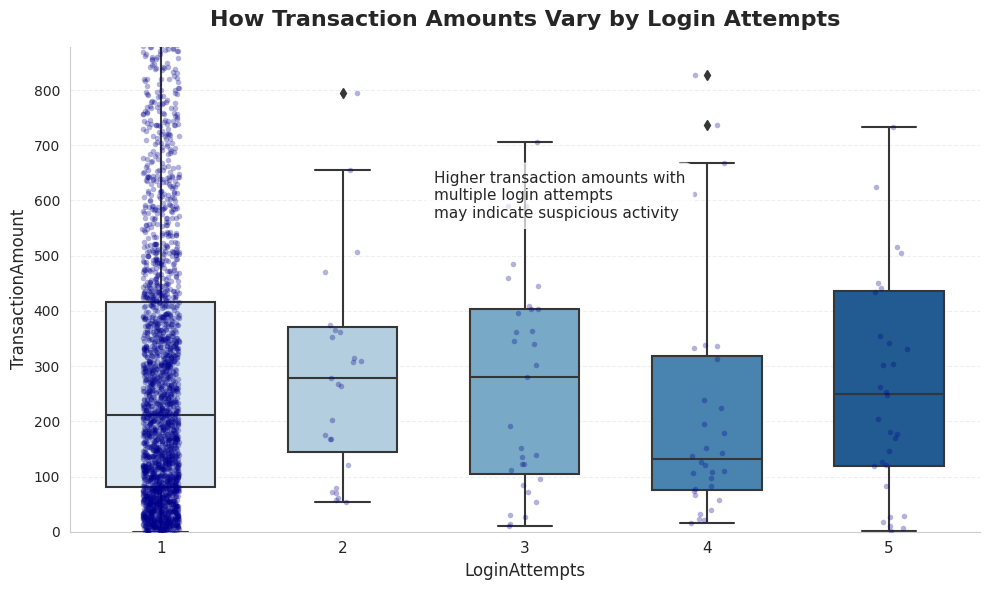

In [15]:
style_plot(title='How Transaction Amounts Vary by Login Attempts', 
           xlabel='Number of Login Attempts', 
           ylabel='Transaction Amount ($)')


sns.boxplot(x='LoginAttempts', y='TransactionAmount', data=df, 
            palette='Blues', width=0.6)

sns.stripplot(x='LoginAttempts', y='TransactionAmount', data=df,
              size=4, color='darkblue', alpha=0.3, jitter=True)


plt.xticks(fontsize=11)
plt.ylim(0, df['TransactionAmount'].quantile(0.95))  # Limit to 95th percentile for clearer visualization

# Add explanatory annotation
plt.annotate('Higher transaction amounts with\nmultiple login attempts\nmay indicate suspicious activity', 
             xy=(2, df[df['LoginAttempts'] > 1]['TransactionAmount'].median()), 
             xytext=(1.5, df['TransactionAmount'].quantile(0.85)),
             fontsize=11,
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7))

# Add a simple grid to help read values
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

**What it shows**: The distribution of transaction amounts for each number of login attempts
- **Fraud Insight**:
    - If transactions with multiple login attempts (e.g., >2) have higher median amounts, it might indicate failed authentication attempts followed by large fraudulent transactions.
    - Wide distributions for higher login attempts could suggest inconsistent behavior, potentially linked to fraud.
- **Why It Helps**: Highlights whether failed logins are a precursor to suspicious transactions, helping us prioritize monitoring for accounts with multiple attempts.


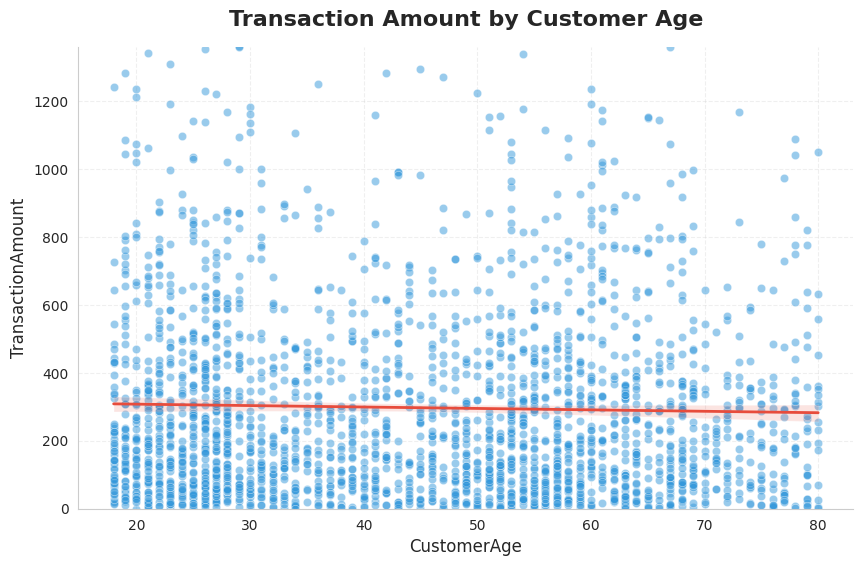

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


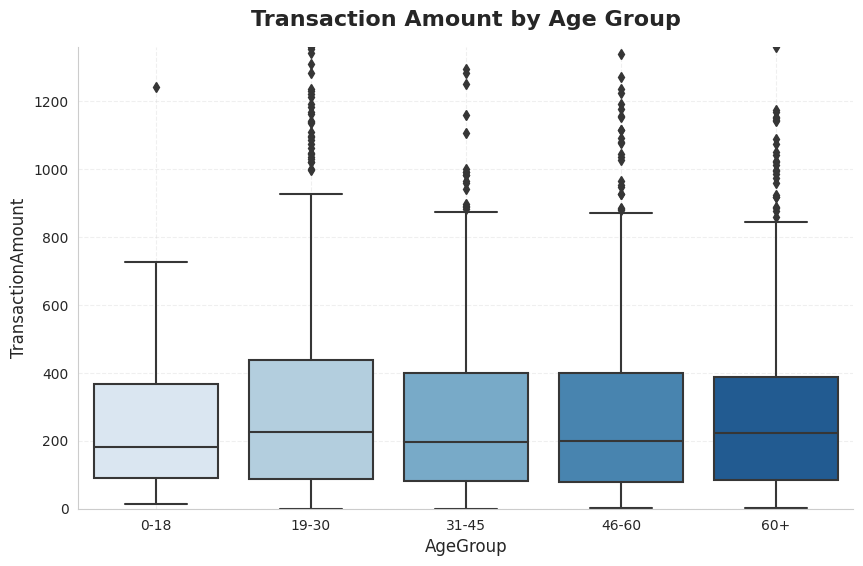

In [16]:
# Create age bins for grouping
df['AgeGroup'] = pd.cut(df['CustomerAge'], bins=[0, 18, 30, 45, 60, 100], 
                        labels=['0-18', '19-30', '31-45', '46-60', '60+'])

# Scatter plot with regression line
style_plot(fig_size=(10, 6), title='Transaction Amount by Customer Age', 
           xlabel='Customer Age', 
           ylabel='Transaction Amount ($)')

sns.scatterplot(x='CustomerAge', y='TransactionAmount', data=df, color='#3498db', alpha=0.5)
sns.regplot(x='CustomerAge', y='TransactionAmount', data=df, scatter=False, color='#e74c3c', 
            line_kws={'lw': 2})

plt.ylim(0, df['TransactionAmount'].quantile(0.99))
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

# Boxplot by age group
style_plot(fig_size=(10, 6), title='Transaction Amount by Age Group', 
           xlabel='Age Group', 
           ylabel='Transaction Amount ($)')

sns.boxplot(x='AgeGroup', y='TransactionAmount', data=df, palette='Blues', linewidth=1.5, fliersize=5)
plt.grid(True, linestyle='--', alpha=0.3)
plt.ylim(0, df['TransactionAmount'].quantile(0.99))
plt.show()

- **What It Shows**:
    - • The scatter plot shows the relationship between age and transaction amount, with a regression line to highlight the trend.
    - • The boxplot groups customers into age bins to compare transaction amount distributions.
- **Fraud Insight**:
    - • Elderly customers (e.g., 60+) with large transactions might be more vulnerable to scams (e.g., phishing or impersonation).
    - • Young customers (e.g., 0-18) with high transactions could indicate stolen accounts, as they’re less likely to have large legitimate transactions.
    - • A steep regression slope (if present) might suggest age-related spending patterns that fraudsters exploit.
- **Why It Helps**: Identifies age groups at higher risk of fraud, enabling targeted interventions (e.g., extra authentication for elderly users).

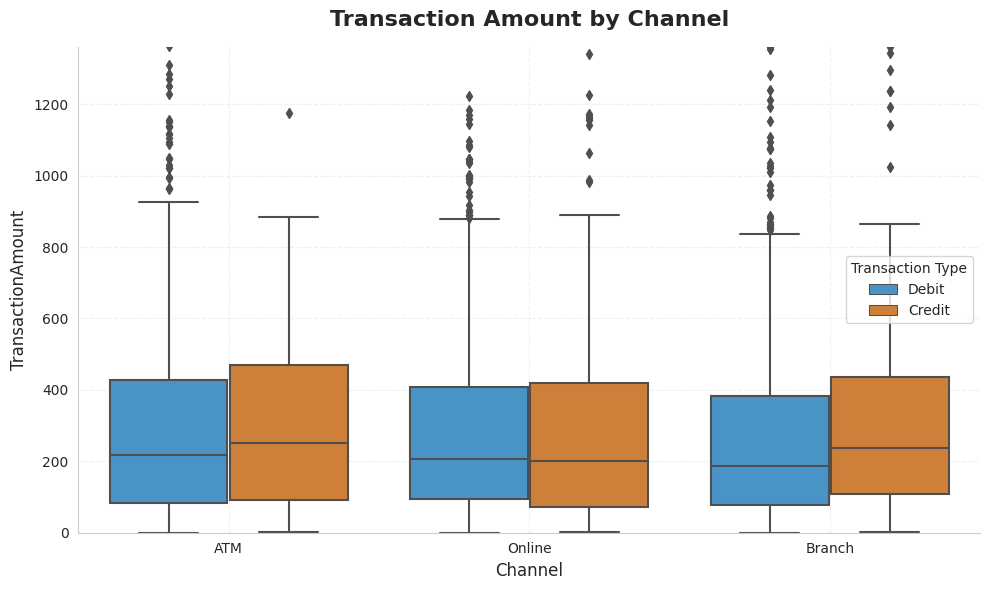

In [17]:
style_plot(fig_size=(10, 6), title='Transaction Amount by Channel', 
           xlabel='Channel', 
           ylabel='Transaction Amount ($)')

# Boxplot with hue for TransactionType
sns.boxplot(x='Channel', y='TransactionAmount', hue='TransactionType', 
            data=df, palette=['#3498db', '#e67e22'], linewidth=1.5, fliersize=5)

# Customize axes and add grid
plt.ylim(0, df['TransactionAmount'].quantile(0.99))  # Limit to 99th percentile
plt.legend(title='Transaction Type', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

- **What It Shows**: Distribution of transaction amounts across Channel categories, split by TransactionType (Debit/Credit).
- **Fraud Insight**:
    - • Higher medians or outliers in Online transactions might suggest e-commerce fraud (e.g., card skimming).
    - • ATM transactions with large debits could indicate cash-out schemes.
- **Why It Helps**: Identifies channels with higher fraud risks, enabling channel-specific monitoring (e.g., extra checks for Online transactions).

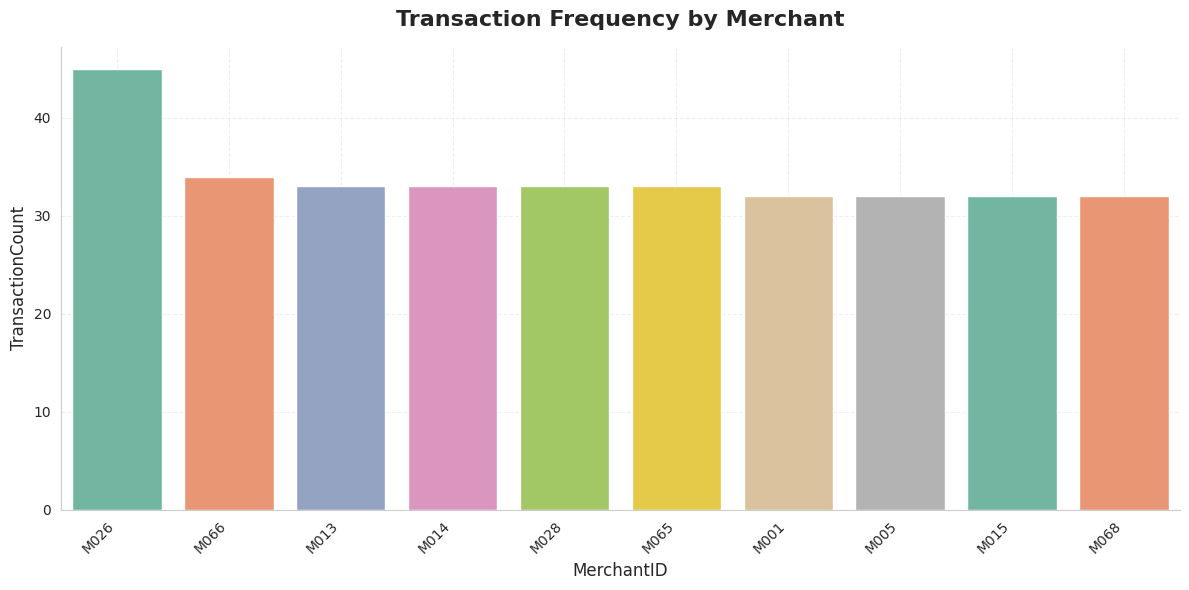

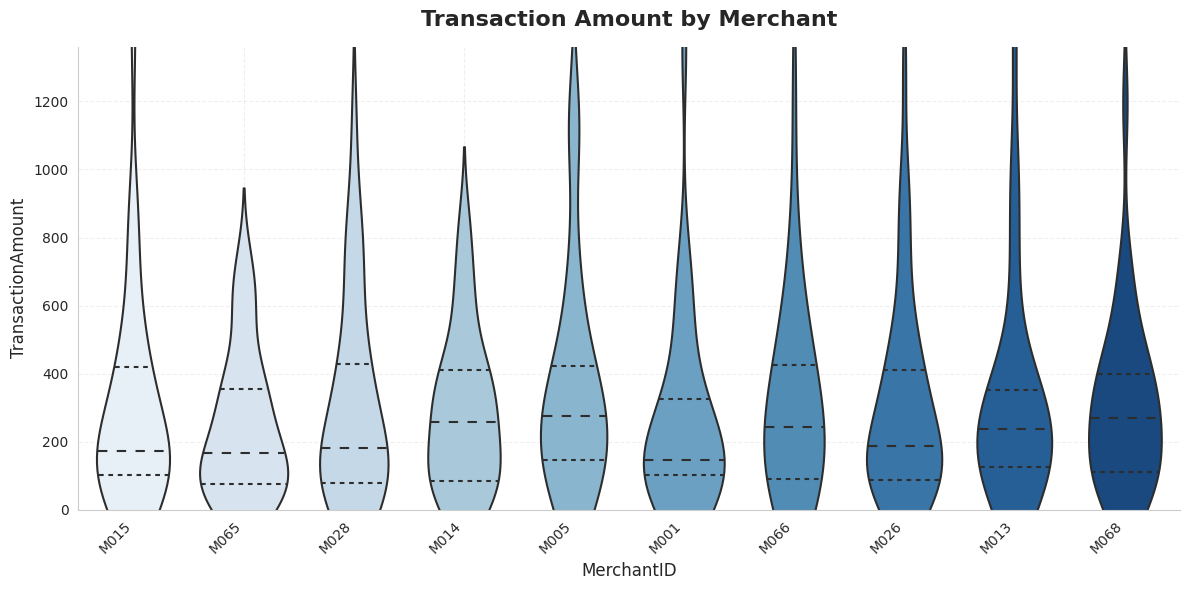

In [18]:
# Aggregate data by MerchantID
merchant_usage = df.groupby('MerchantID').agg({
    'TransactionID': 'count',  # Number of transactions per merchant
    'TransactionAmount': 'mean'  # Average transaction amount per merchant
}).reset_index().rename(columns={'TransactionID': 'TransactionCount'})

# Bar plot for transaction count per MerchantID
style_plot(fig_size=(12, 6), title='Transaction Frequency by Merchant', 
           xlabel='MerchantID', 
           ylabel='Number of Transactions')

# Plot top 10 merchants by transaction count
top_merchants = merchant_usage.nlargest(10, 'TransactionCount')
sns.barplot(x='MerchantID', y='TransactionCount', data=top_merchants, palette='Set2')

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Violin plot for transaction amount by MerchantID
style_plot(fig_size=(12, 6), title='Transaction Amount by Merchant', 
           xlabel='MerchantID', 
           ylabel='Transaction Amount ($)')

sns.violinplot(x='MerchantID', y='TransactionAmount', 
               data=df[df['MerchantID'].isin(top_merchants['MerchantID'])], 
               palette='Blues', inner='quartile', linewidth=1.5)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.ylim(0, df['TransactionAmount'].quantile(0.99))
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

- **What It Shows**:
    - The bar plot shows the number of transactions per MerchantID (top 10 merchants).
    - The violin plot shows the distribution of transaction amounts for these merchants.
- **Fraud Insight**:
    - Merchants with unusually high transaction counts might be involved in fraudulent activity (e.g., fake transactions).
    - Merchants with wide distributions or high medians could be colluding in fraud schemes (e.g., inflated charges).
- **Why It Helps**: Identifies merchants that might be involved in fraud, enabling targeted investigations or restrictions on transactions with those merchants.

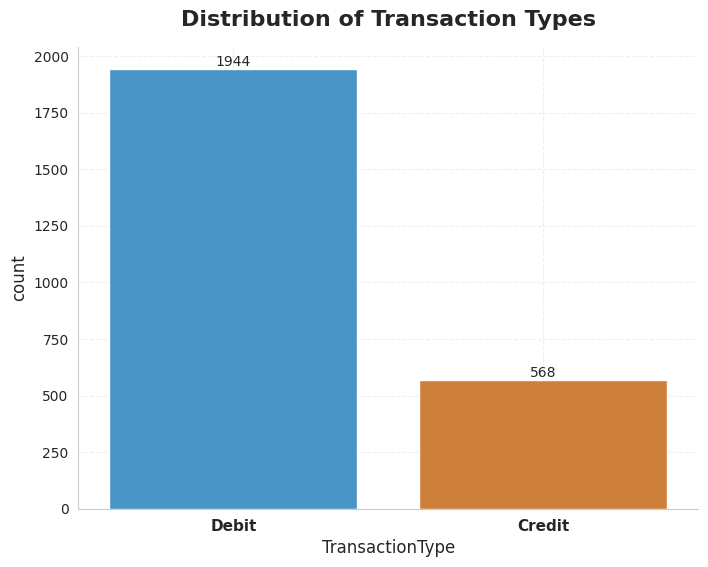

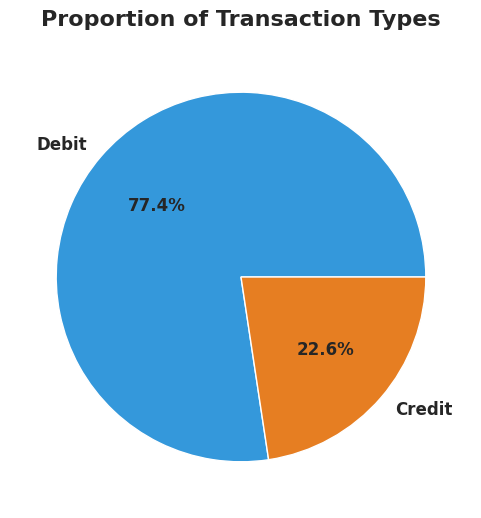

In [19]:
# Count plot for TransactionType
style_plot(fig_size=(8, 6), title='Distribution of Transaction Types', 
           xlabel='Transaction Type', 
           ylabel='Number of Transactions')

# Plot with custom styling
sns.countplot(x='TransactionType', data=df, palette=['#3498db', '#e67e22'])

# Add value labels on top of bars
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10)

plt.xticks(fontsize=11, weight='bold')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

# Pie chart for proportions
plt.figure(figsize=(6, 6))
df['TransactionType'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#3498db', '#e67e22'], 
                                              textprops={'fontsize': 12, 'weight': 'bold'})
plt.title('Proportion of Transaction Types', fontsize=16, weight='bold', pad=15)
plt.ylabel('')  # Remove y-label for pie chart
plt.show()

# Anomaly Detection

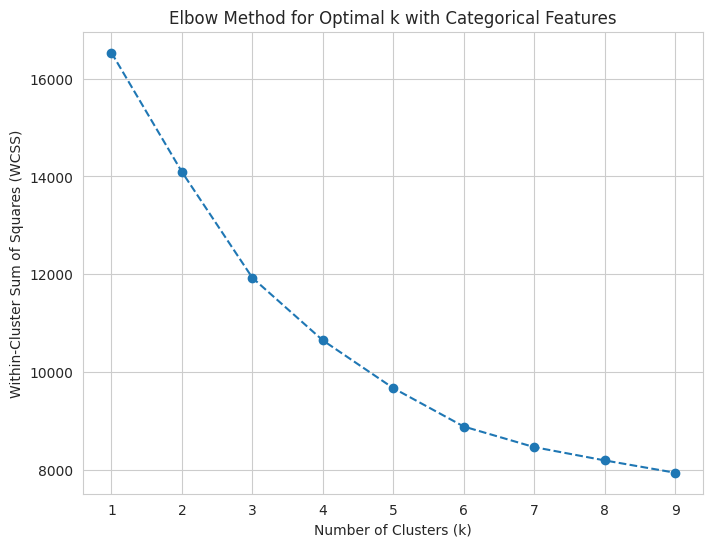

In [20]:

numerical_features = ['TransactionAmount', 'AccountBalance', 'TransactionDuration', 'LoginAttempts', 'CustomerAge']
categorical_features = ['TransactionType', 'Location', 'Channel']

# Numerical data preprocessing
X_num = df[numerical_features]
X_num = X_num.fillna(X_num.median())  # Impute with median
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# Categorical data preprocessing (one-hot encoding)
X_cat = pd.get_dummies(df[categorical_features], drop_first=True)  # drop_first to avoid multicollinearity

# Combine numerical and categorical features
X_combined = np.hstack((X_num_scaled, X_cat.values))

# Calculate WCSS for a range of k values (elbow method)
wcss = []
k_range = range(1, 10)  # Test k from 1 to 10
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_combined)
    wcss.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 6))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.title('Elbow Method for Optimal k with Categorical Features')
plt.grid(True)
plt.show()



In [21]:
# Fit K-means with k=4
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10)
kmeans.fit(X_combined)

# Assign clusters and calculate distance to cluster centroid
df['Cluster'] = kmeans.labels_
df['DistanceToCentroid'] = np.linalg.norm(X_combined - kmeans.cluster_centers_[kmeans.labels_], axis=1)

# Identify potential frauds based on distance threshold (98th percentile)
threshold = df['DistanceToCentroid'].quantile(0.98)
df['PotentialFraud'] = df['DistanceToCentroid'] > threshold
fraud_df = df[df['PotentialFraud']].copy()
print('Total Potential Frauds',fraud_df.shape[0] )
fraud_df

Total Potential Frauds 51


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,...,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,Amount_to_Balance_Ratio,AgeGroup,Cluster,DistanceToCentroid,PotentialFraud
7,TX000008,AC00069,171.42,2023-05-08 17:47:59,Credit,Indianapolis,D000500,92.214.76.157,M020,Branch,...,Retired,291,1,2796.24,2024-11-04 08:10:55,0.061304,60+,1,3.120254,True
113,TX000114,AC00121,213.76,2023-03-01 17:52:14,Credit,Dallas,D000574,51.250.122.123,M009,ATM,...,Retired,282,1,3528.72,2024-11-04 08:09:36,0.060577,60+,1,3.105419,True
146,TX000147,AC00385,973.39,2023-08-30 17:23:20,Debit,Sacramento,D000292,202.194.199.70,M026,Branch,...,Retired,296,1,2042.22,2024-11-04 08:11:44,0.476633,60+,3,3.495565,True
231,TX000232,AC00430,705.60,2023-02-20 18:41:43,Debit,Phoenix,D000103,205.45.234.42,M071,Branch,...,Doctor,124,3,14804.70,2024-11-04 08:09:04,0.047661,31-45,2,3.532689,True
274,TX000275,AC00454,1176.28,2023-12-20 16:08:02,Credit,Kansas City,D000476,50.202.8.53,M074,ATM,...,Engineer,174,5,323.69,2024-11-04 08:11:44,3.633971,46-60,2,4.041652,True
340,TX000341,AC00107,1830.00,2023-03-01 16:31:58,Debit,San Antonio,D000436,62.27.235.199,M082,Online,...,Engineer,238,1,2235.70,2024-11-04 08:11:59,0.818536,46-60,3,4.056678,True
341,TX000342,AC00171,26.06,2023-12-21 17:01:24,Debit,San Diego,D000689,140.212.253.222,M096,ATM,...,Doctor,283,1,12893.63,2024-11-04 08:12:00,0.002021,60+,1,3.083963,True
372,TX000373,AC00069,157.37,2023-11-15 16:54:44,Credit,Dallas,D000001,66.23.166.248,M014,Branch,...,Doctor,289,1,13964.31,2024-11-04 08:10:30,0.011269,31-45,1,3.408387,True
375,TX000376,AC00316,1392.54,2023-11-20 16:51:14,Debit,El Paso,D000113,63.67.150.226,M013,Branch,...,Doctor,297,1,13347.69,2024-11-04 08:09:15,0.104328,31-45,3,3.983739,True
394,TX000395,AC00326,6.30,2023-12-14 18:52:54,Debit,Columbus,D000539,210.160.90.52,M017,Branch,...,Retired,283,5,7697.68,2024-11-04 08:12:13,0.000818,60+,2,3.769686,True


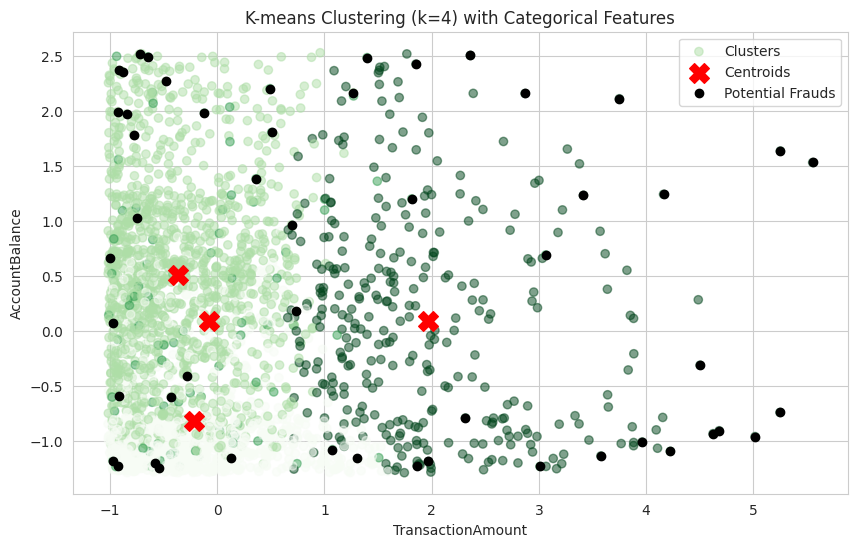

In [22]:

plt.figure(figsize=(10, 6))

# Plot all data points colored by cluster
plt.scatter(X_num_scaled[:, 0], X_num_scaled[:, 1], 
            c=kmeans.labels_, cmap="Greens", alpha=0.5, label='Clusters')

# Plot centroids (projected to the first two dimensions for visualization)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=200, c='red', marker='X', label='Centroids')

# Plot potential fraud points
fraud_indices = df['PotentialFraud']
plt.scatter(X_num_scaled[fraud_indices, 0], X_num_scaled[fraud_indices, 1], 
            c='black', marker='o', label='Potential Frauds')

# Add labels and title
plt.xlabel(numerical_features[0])  # TransactionAmount
plt.ylabel(numerical_features[1])  # AccountBalance
plt.title('K-means Clustering (k=4) with Categorical Features')
plt.legend()
plt.grid(True)
plt.show()